# 03 - The logistic equation: equilibria, phase line, harvesting

**MATH 331 - Differential Equations.** Lecture plan: Session 7 (logistic equation; autonomous equations and the phase line; stability of equilibria).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 1.6, Autonomous equations**: the notation
  $x' = kx(M - x)$, Figure 1.6.2, the example with harvesting (Figures 1.6.5-1.6.7), Exercise
  1.6.4. Section 1.3 (separable equations).
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012), Section 1.1,
  Exercise 2 (the logistic growth law from births and deaths).
* Exercise numbers of Lebl are those of the lists at the end of each chapter of the LibreTexts
  edition.
* Related notebooks: 01 (exponential growth), 09 (slope fields), 10 (separable equations), 13
  (equilibrium and time constant), **03E** (optional: blow-up, Euler's false oscillations, the
  bifurcation). Video R04 (partial fractions).

**What you will learn**
1. Why the logistic law is the natural correction of exponential growth.
2. How to find the long-term behaviour **without solving**: equilibria, phase line, stability.
3. The exact solution, and the S-shaped curve.
4. What happens when the population is harvested, and why there is a harvest that must not be
   exceeded.

## 1. Theory in brief

**The model.** With limited resources the growth rate per individual falls as the population
grows, and vanishes at a population $M$:

$$ \boxed{\;\frac{dx}{dt} = k\,x\,(M - x), \qquad x(0) = x_0, \qquad k > 0,\ M > 0\;} $$

$M$ is the **limiting population** (carrying capacity). The equation is of first order,
**nonlinear** (it contains $x^2$), autonomous and separable.

**Equilibria.** For an autonomous equation $x' = f(x)$, the solutions of $f(x) = 0$ are constant
solutions. Here $x = 0$ and $x = M$.

**Phase line.** Between two equilibria $f$ keeps its sign: where $f > 0$ every solution rises,
where $f < 0$ it falls. No solution can cross an equilibrium.

**Stability.** An equilibrium $x^*$ is **stable** when the solutions that start near it stay near
it (both arrows of the phase line point towards it), **unstable** otherwise. A quick test:
stable if $f'(x^*) < 0$, unstable if $f'(x^*) > 0$. Here $x = M$ is stable and $x = 0$ unstable.

**The solution** (for $x_0 > 0$): $\;x(t) = \dfrac{M\,x_0}{x_0 + (M - x_0)\,e^{-kMt}}$, which tends
to $M$.

**Harvesting.** $x' = kx(M - x) - h$ has two equilibria if $h < \dfrac{kM^2}{4}$, one if
$h = \dfrac{kM^2}{4}$, none beyond: the population collapses.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: logistic_solution, harvesting_equilibria, phase_line, slope_field, classify_equilibrium, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. The model

Exponential growth (notebook 01) assumes that each individual contributes the same growth,
whatever the size of the population: $\dfrac{1}{x}\dfrac{dx}{dt} = $ constant. When food and space
are limited this cannot last. The simplest correction lets the growth per individual decrease in
a straight line, down to zero at the population $M$:

$$ \frac{1}{x}\frac{dx}{dt} = k\,(M - x) \qquad\Longrightarrow\qquad \frac{dx}{dt} = k\,x\,(M - x) $$

(Lebl, Section 1.6). For a small population $x' \approx kM\,x$: exponential growth with rate
$kM$. Biologists write the same equation as $x' = r\,x\,(1 - x/K)$, with $r = kM$ and $K = M$.

*Another way to get it* (Adkins and Davidson, Section 1.1, Exercise 2): births proportional to
the population, $b\,x$; deaths proportional to its square, $d\,x^2$ (crowding: meetings between
two individuals). Then $x' = bx - dx^2 = d\,x\,(b/d - x)$: logistic, with $k = d$ and $M = b/d$.

## 3. Without solving: equilibria and the phase line

By hand, for $f(x) = kx(M - x)$:

* $f(x) = 0$ for $x = 0$ and $x = M$: two equilibria.
* $f > 0$ for $0 < x < M$: the solutions rise. $f < 0$ for $x > M$ and for $x < 0$: they fall.
* So the arrows of the phase line point **towards** $M$ from both sides (stable) and **away**
  from $0$ (unstable).
* The quick test agrees: $f'(x) = kM - 2kx$, so $f'(M) = -kM < 0$ and $f'(0) = kM > 0$.

Conclusion, before any formula: **every solution that starts with $x_0 > 0$ tends to $M$.**

The picture uses Lebl's numbers of Figure 1.6.2: $x' = 0.1\,x\,(5 - x)$.

equilibrium x = 0:  f' = M*k
equilibrium x = M:  f' = -M*k
x = 0: f' = +0.50  ->  unstable
x = 5: f' = -0.50  ->  stable


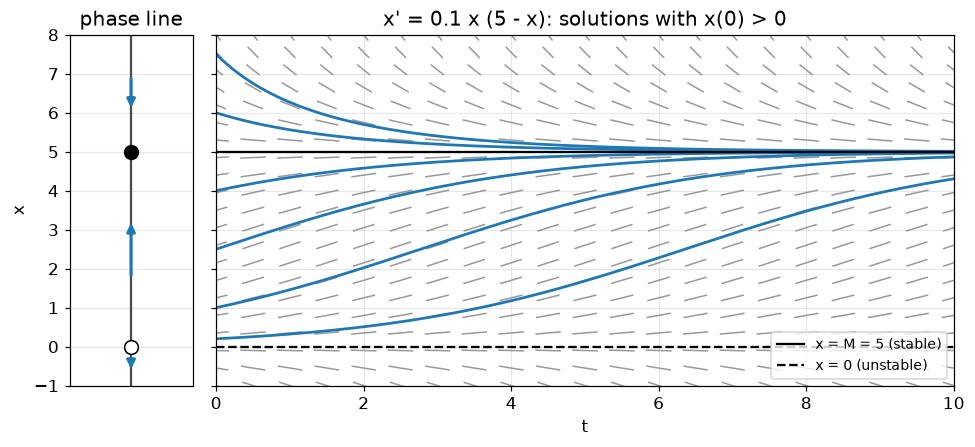

In [2]:
x, k, M = sp.symbols("x k M", positive=True)
f = k * x * (M - x)
for point in (sp.Integer(0), M):
    slope = sp.simplify(sp.diff(f, x).subs(x, point))
    print(f"equilibrium x = {point}:  f' = {slope}")

K_LEBL, M_LEBL = 0.1, 5.0                   # Lebl, Figure 1.6.2
T_END = 10.0
X_WINDOW = (-1.0, 8.0)
START_VALUES = (0.2, 1.0, 2.5, 4.0, 6.0, 7.5)
PANEL_WIDTHS = (1, 6)
TWO_PANELS = (9.0, 4.2)
N_POINTS = 400


def logistic_rate(value, k=K_LEBL, M=M_LEBL):
    return k * value * (M - value)


for point in (0.0, M_LEBL):
    derivative = K_LEBL * M_LEBL - 2 * K_LEBL * point
    print(f"x = {point:g}: f' = {derivative:+.2f}  ->  {ol.classify_equilibrium(derivative)}")

times = np.linspace(0.0, T_END, N_POINTS)
fig, (line_ax, ax) = plt.subplots(1, 2, figsize=TWO_PANELS, sharey=True, gridspec_kw={"width_ratios": PANEL_WIDTHS})
ol.phase_line(line_ax, logistic_rate, [0.0, M_LEBL], X_WINDOW)
line_ax.set_ylabel("x")
line_ax.set_title("phase line")
ol.slope_field(ax, lambda tt, xx: logistic_rate(xx), (0.0, T_END), X_WINDOW)
for start in START_VALUES:
    ax.plot(times, ol.logistic_solution(times, start, K_LEBL, M_LEBL), "-", color="tab:blue", linewidth=1.8)
ax.axhline(M_LEBL, color="black", linewidth=1.5, linestyle="-", label="x = M = 5 (stable)")
ax.axhline(0.0, color="black", linewidth=1.5, linestyle="--", label="x = 0 (unstable)")
ax.set_xlabel("t")
ax.set_title("x' = 0.1 x (5 - x): solutions with x(0) > 0")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

assert ol.classify_equilibrium(-K_LEBL * M_LEBL) == "stable" and ol.classify_equilibrium(K_LEBL * M_LEBL) == "unstable"

*The plot shows*, on the left, the phase line: a vertical line with a filled dot at $x = 5$
(stable), an open dot at $x = 0$ (unstable), an arrow pointing up between them and arrows
pointing down above 5 and below 0. On the right, the slope field with six solutions starting
from 0.2, 1, 2.5, 4, 6 and 7.5: those that start below 2.5 rise to 5 in an S-shaped curve, those
between 2.5 and 5 rise bending downwards all the way, those above 5 fall to it. None crosses the solid line $x = 5$ or the dashed line $x = 0$.

What happens below the dashed line, for a negative start, is in the optional notebook 03E.

## 4. The exact solution

The equation is separable (notebook 10). The constant solutions are $x = 0$ and $x = M$ (step 0).
For the others:

$$ \frac{dx}{x\,(M - x)} = k\,dt, \qquad \frac{1}{x\,(M - x)} = \frac{1}{M}\Big(\frac1x + \frac{1}{M - x}\Big) $$

(partial fractions, video R04). Integrating, for $0 < x < M$:

$$ \frac{1}{M}\,\ln\frac{x}{M - x} = k\,t + C \quad\Longrightarrow\quad \frac{x}{M - x} = D\,e^{kMt},
\qquad D = \frac{x_0}{M - x_0}, $$

and solving for $x$:

$$ \boxed{\;x(t) = \frac{M\,x_0}{x_0 + (M - x_0)\,e^{-kMt}}\;} $$

The same formula holds for $x_0 > M$, and it gives the constant solutions for $x_0 = 0$ and
$x_0 = M$.

**Reading the formula.** As $t \to \infty$ the exponential dies and $x \to M$, as the phase line
said. For $x_0 < M/2$ the growth is fastest when the curve crosses $x = M/2$, at
$\;t = \dfrac{1}{kM}\ln\dfrac{M - x_0}{x_0}$: there the curve changes from bending up to bending
down (the S shape), and the rate is the largest possible, $\dfrac{kM^2}{4}$.

In [3]:
t, x_0 = sp.symbols("t x_0", positive=True)


def residual(left, right=0):
    # left side minus right side of an equation, simplified: 0 for a solution (notebook 09)
    return sp.simplify(left - right)


assert residual(1 / (x * (M - x)), (1 / x + 1 / (M - x)) / M) == 0          # the partial fractions

formula = M * x_0 / (x_0 + (M - x_0) * sp.exp(-k * M * t))
print("residual of the formula:", residual(sp.diff(formula, t), k * formula * (M - formula)))
print("value at t = 0:", sp.simplify(formula.subs(t, 0)))
print("time at which x = M/2:", sp.simplify(sp.solve(sp.Eq(formula, M / 2), t)[0]))
print("largest growth rate, at x = M/2:", f.subs(x, M / 2))

assert residual(sp.diff(formula, t), k * formula * (M - formula)) == 0
assert sp.simplify(formula.subs(t, 0) - x_0) == 0

residual of the formula: 0
value at t = 0: x_0
time at which x = M/2: log((M - x_0)/x_0)/(M*k)
largest growth rate, at x = M/2: M**2*k/4


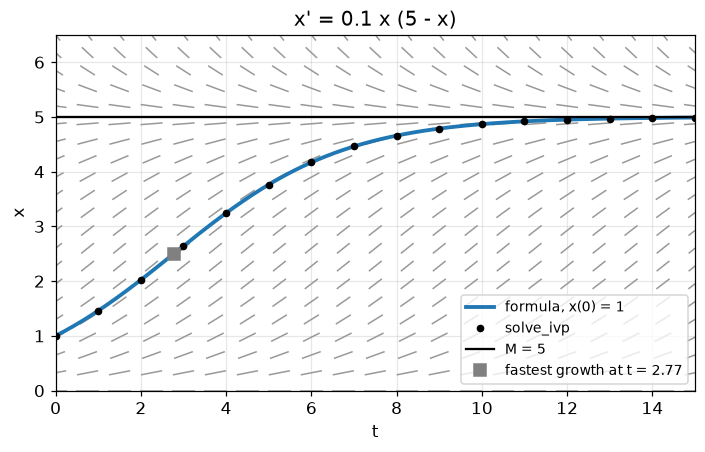

In [4]:
FIGURE_SIZE = (7.5, 4.2)
START = 1.0
LONG_TIME = 15.0
N_DOTS = 16
TOLERANCE = 1e-9
ABOVE = 1.3                                 # the window reaches a little above the highest value


def plot_logistic(k=K_LEBL, M=M_LEBL, x0=START, t_end=LONG_TIME):
    # the exact solution, the two equilibria, the point of fastest growth, and a numerical check
    times = np.linspace(0.0, t_end, N_POINTS)
    dots = np.linspace(0.0, t_end, N_DOTS)
    numerical = solve_ivp(lambda tt, xx: k * xx * (M - xx), (0.0, t_end), [x0], dense_output=True,
                          rtol=TOLERANCE, atol=TOLERANCE)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ol.slope_field(ax, lambda tt, xx: k * xx * (M - xx), (0.0, t_end), (0.0, ABOVE * max(M, x0)))
    ax.plot(times, ol.logistic_solution(times, x0, k, M), "-", linewidth=2.5, label=f"formula, x(0) = {x0:g}")
    ax.plot(dots, numerical.sol(dots)[0], "o", color="black", markersize=4, label="solve_ivp")
    ax.axhline(M, color="black", linewidth=1.5, label=f"M = {M:g}")
    if 0 < x0 < M / 2:
        fastest = np.log((M - x0) / x0) / (k * M)
        if fastest <= t_end:
            ax.plot(fastest, M / 2, "s", color="gray", markersize=8, label=f"fastest growth at t = {fastest:.2f}")
    ax.set_xlabel("t")
    ax.set_ylabel("x")
    ax.set_title(f"x' = {k:g} x ({M:g} - x)")
    ax.legend(loc="lower right")
    plt.show()


plot_logistic()
fastest_time = np.log((M_LEBL - START) / START) / (K_LEBL * M_LEBL)
assert np.isclose(ol.logistic_solution(fastest_time, START, K_LEBL, M_LEBL), M_LEBL / 2)

*The plot shows* the solution of $x' = 0.1\,x\,(5 - x)$ that starts from 1: an S-shaped curve
that first bends upwards, is steepest at the grey square ($x = 2.5$, at $t = 2.77$) and then
flattens towards the black line $x = 5$. The black dots (numerical solution) lie on the curve.

**Sliders.** Answer *before* moving them:

1. If $k$ is doubled, does the limit change? What changes?
2. Start from $x(0) = 7$, above $M$: what does the curve look like? Is there a point of fastest
   growth?
3. Start very close to 0, for example $x(0) = 0.1$: what happens to the time of fastest growth?

In [5]:
K_RANGE = (0.01, 0.5, 0.01)                 # minimum, maximum, step
M_RANGE = (1.0, 10.0, 0.5)
X0_RANGE = (0.1, 12.0, 0.1)
TIME_RANGE = (2.0, 50.0, 1.0)

interact(plot_logistic,
         k=FloatSlider(value=K_LEBL, min=K_RANGE[0], max=K_RANGE[1], step=K_RANGE[2], description="k",
                       continuous_update=False),
         M=FloatSlider(value=M_LEBL, min=M_RANGE[0], max=M_RANGE[1], step=M_RANGE[2], description="M",
                       continuous_update=False),
         x0=FloatSlider(value=START, min=X0_RANGE[0], max=X0_RANGE[1], step=X0_RANGE[2], description="x(0)",
                        continuous_update=False),
         t_end=FloatSlider(value=LONG_TIME, min=TIME_RANGE[0], max=TIME_RANGE[1], step=TIME_RANGE[2],
                           description="t max", continuous_update=False));

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='k', max=0.5, min=0.01, step...

(1: the limit is still $M$; everything happens twice as fast, because $k$ only appears in the
product $kMt$. 2: the curve falls towards $M$, always bending the same way: no S. 3: it comes
later: a small population needs time to become visible, then the growth takes off.)

## 5. Harvesting

Now individuals are removed at a constant rate $h$ (fishing, hunting; Lebl's example in Section
1.6):

$$ \frac{dx}{dt} = k\,x\,(M - x) - h . $$

Without solving, again: the equilibria are the solutions of $kx(M - x) = h$, that is of
$kx^2 - kMx + h = 0$:

$$ A,\ B = \frac{kM \pm \sqrt{(kM)^2 - 4hk}}{2k} . $$

The parabola $kx(M - x)$ has its maximum $\dfrac{kM^2}{4}$ at $x = M/2$ (the largest growth rate
of Section 4), so:

| Harvest | Equilibria | What happens |
|---|---|---|
| $h < \dfrac{kM^2}{4}$ | two, $B < A$ | $A$ is stable, $B$ unstable: the population survives if it starts above $B$ |
| $h = \dfrac{kM^2}{4}$ | one, $A = B = \dfrac M2$ | it attracts from above only: any drop below it is fatal |
| $h > \dfrac{kM^2}{4}$ | none | the population collapses, whatever its size |

**Lebl's numbers:** $M = 8$, $k = 0.1$. With $h = 1$: $B \approx 1.55$ and $A \approx 6.45$. With
$h = 1.6$: $A = B = 4$. With $h = 2$: no equilibrium (Figures 1.6.5-1.6.7).

In [6]:
K_HARVEST, M_HARVEST = 0.1, 8.0             # Lebl's example
HARVESTS = (1.0, 1.6, 2.0)
critical_harvest = K_HARVEST * M_HARVEST ** 2 / 4

for harvest in HARVESTS:
    print(f"h = {harvest}: equilibria {np.round(ol.harvesting_equilibria(K_HARVEST, M_HARVEST, harvest), 2)}")
print(f"critical harvest k M^2 / 4 = {critical_harvest:.2f}")

assert np.allclose(ol.harvesting_equilibria(K_HARVEST, M_HARVEST, HARVESTS[0]), (1.55, 6.45), atol=0.005)
assert np.allclose(ol.harvesting_equilibria(K_HARVEST, M_HARVEST, HARVESTS[1]), (4.0,))
assert ol.harvesting_equilibria(K_HARVEST, M_HARVEST, HARVESTS[2]) == ()

h = 1.0: equilibria [1.55 6.45]
h = 1.6: equilibria [4.]
h = 2.0: equilibria []
critical harvest k M^2 / 4 = 1.60


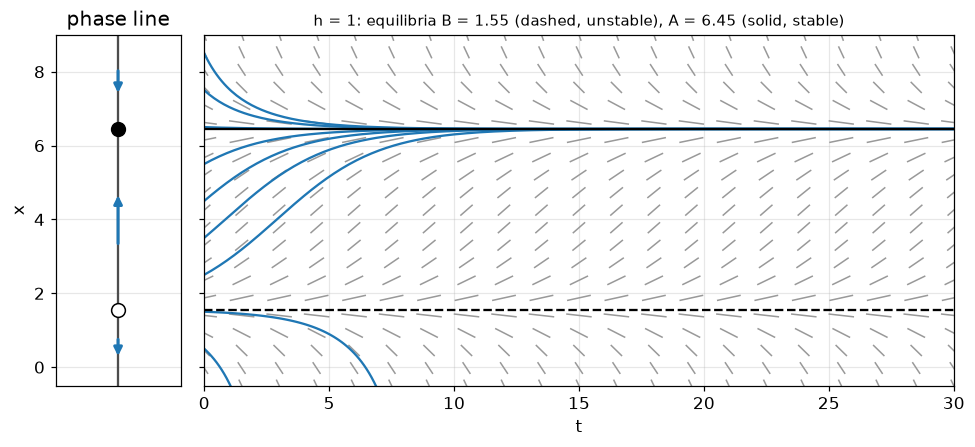

In [7]:
HARVEST_TIME = 30.0
BELOW_ZERO = -0.5                           # the picture shows a little below x = 0
N_STARTS = 9
MAX_STEP = 0.1


def plot_harvest(h=HARVESTS[0], k=K_HARVEST, M=M_HARVEST, t_end=HARVEST_TIME):
    # phase line, slope field and solutions of x' = k x (M - x) - h
    def rate(value):
        return k * value * (M - value) - h

    window = (BELOW_ZERO, M + 1.0)
    equilibria = ol.harvesting_equilibria(k, M, h)
    fig, (line_ax, ax) = plt.subplots(1, 2, figsize=TWO_PANELS, sharey=True, gridspec_kw={"width_ratios": PANEL_WIDTHS})
    ol.phase_line(line_ax, rate, list(equilibria), window)
    line_ax.set_ylabel("x")
    line_ax.set_title("phase line")
    ol.slope_field(ax, lambda tt, xx: rate(xx), (0.0, t_end), window)
    for start in np.linspace(0.5, M + 0.5, N_STARTS):
        gone = lambda tt, xx: xx[0] - BELOW_ZERO                # noqa: E731  (stop when the population is gone)
        gone.terminal = True
        curve = solve_ivp(lambda tt, xx: rate(xx), (0.0, t_end), [start], max_step=MAX_STEP, events=gone)
        ax.plot(curve.t, curve.y[0], "-", color="tab:blue", linewidth=1.5)
    for level, style in zip(equilibria[::-1], ("-", "--")):
        ax.axhline(level, color="black", linewidth=1.5, linestyle=style)
    if len(equilibria) == 2:
        what = f"equilibria B = {equilibria[0]:.2f} (dashed, unstable), A = {equilibria[1]:.2f} (solid, stable)"
    elif len(equilibria) == 1:
        what = f"one equilibrium, {equilibria[0]:.2f}: the critical harvest"
    else:
        what = "no equilibrium: collapse"
    ax.set_xlabel("t")
    ax.set_title(f"h = {h:g}: {what}", fontsize=10)
    plt.tight_layout()
    plt.show()


plot_harvest()

*The plot shows* Lebl's example with harvest $h = 1$. On the phase line: a filled dot at
$A = 6.45$ (stable) and an open dot at $B = 1.55$ (unstable). On the right, nine solutions: those
that start above the dashed line $B$ go to the solid line $A$; the two that start below $B$ (from
0.5 and from 1.5) fall, reach zero within seven time units and leave the picture: the population
is gone.

**Sliders.** Before moving the harvest $h$: what do you expect at $h = 1.6$? And at $h = 1.7$,
only a little more?

In [8]:
H_RANGE = (0.0, 2.5, 0.05)                  # minimum, maximum, step
K_HARVEST_RANGE = (0.05, 0.3, 0.01)
M_HARVEST_RANGE = (2.0, 12.0, 0.5)
HARVEST_TIME_RANGE = (5.0, 80.0, 5.0)

interact(plot_harvest,
         h=FloatSlider(value=HARVESTS[0], min=H_RANGE[0], max=H_RANGE[1], step=H_RANGE[2], description="h",
                       continuous_update=False),
         k=FloatSlider(value=K_HARVEST, min=K_HARVEST_RANGE[0], max=K_HARVEST_RANGE[1], step=K_HARVEST_RANGE[2],
                       description="k", continuous_update=False),
         M=FloatSlider(value=M_HARVEST, min=M_HARVEST_RANGE[0], max=M_HARVEST_RANGE[1], step=M_HARVEST_RANGE[2],
                       description="M", continuous_update=False),
         t_end=FloatSlider(value=HARVEST_TIME, min=HARVEST_TIME_RANGE[0], max=HARVEST_TIME_RANGE[1],
                           step=HARVEST_TIME_RANGE[2], description="t max", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='h', max=2.5, step=0.05), Fl...

(At $h = 1.6$ the two equilibria meet at $x = 4$: solutions from above still settle there, slowly, but
the smallest drop below 4 leads to collapse. At $h = 1.7$ there is no equilibrium at all: every
solution collapses. A small increase of the harvest changes everything: the optional notebook
03E looks at this *bifurcation* more closely.)

**The lesson for a fishery:** the largest harvest that can be sustained is $kM^2/4$, and running
exactly at it leaves no margin for a bad year.

## 6. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

For $x' = 0.1\,x\,(5 - x)$, use the phase line (no formula) to say where the solution goes as
$t \to \infty$ when it starts from $x(0) = 1$, from $x(0) = 6$ and from $x(0) = 0$. Type the three
limits in a list.

In [9]:
my_limits = None                # [from x(0) = 1, from x(0) = 6, from x(0) = 0]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 1", my_limits, [M_LEBL, M_LEBL, 0.0]);

Exercise 1: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Lebl, Section 1.6, the example with harvesting.* For $x' = 0.1\,x\,(8 - x) - h$: find the
two equilibria for $h = 1$ (two decimals), and the critical harvest.

**(b)** For $x' = 0.1\,x\,(5 - x)$, $x(0) = 1$: at what time is the growth fastest? (Two
decimals.) And how large is the growth rate $x'$ at that moment?

In [10]:
my_equilibria = None            # (a): [the smaller, the larger]
my_critical_harvest = None      # (a)
my_fastest_time = None          # (b)
my_fastest_rate = None          # (b)
# ---- your answers go above this line; the lines below check them (nothing to change) ----

TWO_DECIMALS = 1e-2
ol.check("Exercise 2a, equilibria", my_equilibria, ol.harvesting_equilibria(K_HARVEST, M_HARVEST, HARVESTS[0]),
         tol=TWO_DECIMALS)
ol.check("Exercise 2a, critical harvest", my_critical_harvest, critical_harvest, tol=TWO_DECIMALS)
ol.check("Exercise 2b, time", my_fastest_time, fastest_time, tol=TWO_DECIMALS)
ol.check("Exercise 2b, rate", my_fastest_rate, K_LEBL * M_LEBL ** 2 / 4, tol=TWO_DECIMALS);

Exercise 2a, equilibria: no answer yet (replace None with your value)
Exercise 2a, critical harvest: no answer yet (replace None with your value)
Exercise 2b, time: no answer yet (replace None with your value)
Exercise 2b, rate: no answer yet (replace None with your value)


### Exercise 3 - Fill in

Complete the function `harvested`, the right-hand side of the logistic equation with harvesting,
$k\,x\,(M - x) - h$. The next cell checks it at the equilibria of Lebl's example and tells you,
from the sign of your function on each side, which one is stable.

In [11]:
def harvested(x, k, M, h):
    return None                 # replace None with the formula

In [12]:
if harvested(1.0, K_HARVEST, M_HARVEST, HARVESTS[0]) is None:
    print("Exercise 3: complete harvested first")
else:
    STEP_ASIDE = 0.1            # how far from an equilibrium the sign is tested
    smaller, larger = ol.harvesting_equilibria(K_HARVEST, M_HARVEST, HARVESTS[0])
    for equilibrium in (smaller, larger):
        assert np.isclose(harvested(equilibrium, K_HARVEST, M_HARVEST, HARVESTS[0]), 0.0, atol=1e-9), \
            f"your function is not zero at the equilibrium {equilibrium:.2f}"
    assert np.isclose(harvested(M_HARVEST / 2, K_HARVEST, M_HARVEST, critical_harvest), 0.0), \
        "at the critical harvest x = M/2 must be an equilibrium"
    assert np.isclose(harvested(2.0, K_HARVEST, M_HARVEST, 0.0), K_HARVEST * 2.0 * (M_HARVEST - 2.0)), \
        "with h = 0 it must be the logistic equation"
    for equilibrium in (smaller, larger):
        below = harvested(equilibrium - STEP_ASIDE, K_HARVEST, M_HARVEST, HARVESTS[0])
        above = harvested(equilibrium + STEP_ASIDE, K_HARVEST, M_HARVEST, HARVESTS[0])
        print(f"x = {equilibrium:.2f}: x' is {below:+.3f} just below and {above:+.3f} just above ->",
              "stable" if below > 0 > above else "unstable")
    print("Exercise 3: correct")

Exercise 3: complete harvested first


### Exercise 4 - Explore

*Lebl, Exercise 1.6.4.* Harvest an amount **proportional** to the population: $h\,x$ per unit of
time, instead of the constant $h$.

* Write the differential equation.
* Show that if $kM > h$ the equation is still logistic. What is the new limiting population?
* What happens when $kM < h$?
* Try it: copy `plot_harvest` and change two things, the formula inside `rate` and the list of
  equilibria (now $0$ and $M - h/k$). Compare the two ways of harvesting for $k = 0.1$, $M = 8$.
  Which one is safer for the population? Why?

In [13]:
# your code here

## 7. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. `[5, 5, 0]`: every positive start goes to $M = 5$; $x = 0$ is an equilibrium, so a solution
   that starts there stays there.
2. (a) $B \approx 1.55$, $A \approx 6.45$; critical harvest $kM^2/4 = 1.6$. (b)
   $t = \dfrac{\ln 4}{0.5} \approx 2.77$; the rate there is $kM^2/4 = 0.625$.
3. `return k * x * (M - x) - h`; $B = 1.55$ is unstable, $A = 6.45$ is stable.
4. $x' = kx(M - x) - hx = k\,x\,\big(M - \tfrac hk - x\big)$: logistic with limiting population
   $M - \tfrac hk$ when $kM > h$. When $kM < h$ the only equilibrium that matters is $x = 0$, and
   it is stable: the population dies out, but slowly, never falling below zero in a finite time.
   Proportional harvesting is safer: the catch shrinks when the population shrinks.

</details>

**Where to go next:** notebook 13 (other models with an equilibrium), notebook 03E (optional:
negative starts and blow-up, Euler's false oscillations, the bifurcation), notebook 04 (Euler's
method).